# Lesson 1.2: Describing the penguins

Here we check every number from the lesson: the mean and the median, the spread, the shape, and what changes when we split by species. Run the cells from top to bottom. You don't need to change anything.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Find the data file, wherever this notebook is opened from
here = Path.cwd()
folder = next(p / "data/penguins" for p in [here, *here.parents] if (p / "data/penguins/penguins.csv").exists())
df = pd.read_csv(folder / "penguins.csv")
mass = df["body_mass_g"].dropna()
print("penguins:", len(df), " with a body mass:", len(mass))

penguins: 344  with a body mass: 342


## Step 1 and 2: count, then the mean and the median

In [2]:
print("mean:  ", round(mass.mean(), 1))
print("median:", mass.median())

mean:   4201.8
median: 4050.0


### One typo

Lesson 1.1's messy file had a penguin at 42,500 g, a typo for 4,250. Watch what one wrong value does to each.

In [3]:
with_typo = pd.concat([mass, pd.Series([42500])])
print("mean with the typo:  ", round(with_typo.mean(), 1))
print("median with the typo:", with_typo.median())

mean with the typo:   4313.4
median with the typo: 4050.0


## Step 3: the spread

In [4]:
q1, q3 = mass.quantile([0.25, 0.75])
print("range:        ", mass.min(), "to", mass.max())
print("middle half:  ", q1, "to", q3)
print("std deviation:", round(mass.std(), 1))

low, high = mass.mean() - mass.std(), mass.mean() + mass.std()
inside = mass.between(low, high).sum()
print(f"within one std of the mean ({low:.0f} to {high:.0f} g): {inside} of {len(mass)}")
print("within 100 g of the mean:", (abs(mass - mass.mean()) <= 100).sum())

range:         2700.0 to 6300.0
middle half:   3550.0 to 4750.0
std deviation: 802.0
within one std of the mean (3400 to 5004 g): 231 of 342
within 100 g of the mean: 25


`describe()` gives most of these in one line, for every number column.

In [5]:
df.describe().round(1)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.0,342.0,342.0,342.0
mean,43.9,17.2,200.9,4201.8
std,5.5,2.0,14.1,802.0
min,32.1,13.1,172.0,2700.0
25%,39.2,15.6,190.0,3550.0
50%,44.4,17.3,197.0,4050.0
75%,48.5,18.7,213.0,4750.0
max,59.6,21.5,231.0,6300.0


## Step 4: the shape

A histogram puts the values into bins and counts how many fall in each.

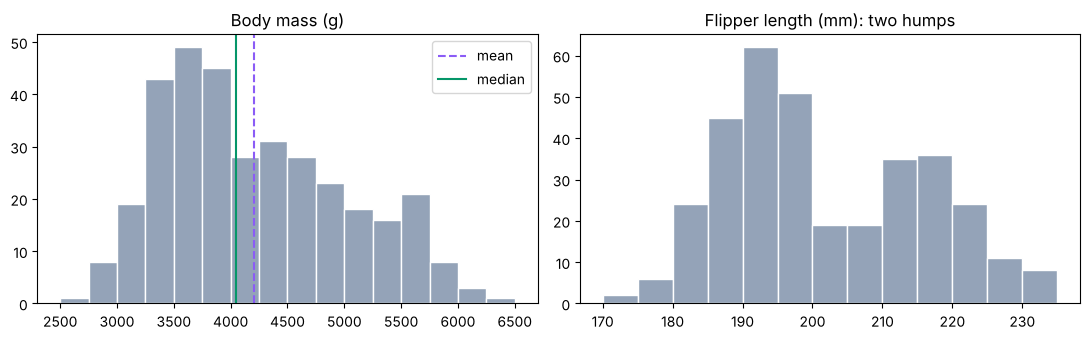

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(mass, bins=range(2500, 6501, 250), color="#94a3b8", edgecolor="white")
axes[0].axvline(mass.mean(), color="#8b5cf6", linestyle="--", label="mean")
axes[0].axvline(mass.median(), color="#059669", label="median")
axes[0].set_title("Body mass (g)")
axes[0].legend()
axes[1].hist(df["flipper_length_mm"].dropna(), bins=range(170, 236, 5), color="#94a3b8", edgecolor="white")
axes[1].set_title("Flipper length (mm): two humps")
plt.tight_layout()
plt.show()

## Step 5: split by group

In [7]:
df.groupby("species")["body_mass_g"].agg(["count", "mean", "median", "std"]).round(1)

,count,mean,median,std
species,,,,
Adelie,151,3700.7,3700.0,458.6
Chinstrap,68,3733.1,3700.0,384.3
Gentoo,123,5076.0,5000.0,504.1


In [8]:
df.groupby(["species", "sex"])["body_mass_g"].agg(["count", "mean", "std"]).round(1)

count    mean    std
species   sex                         
Adelie    FEMALE     73  3368.8  269.4
          MALE       73  4043.5  346.8
Chinstrap FEMALE     34  3527.2  285.3
          MALE       34  3939.0  362.1
Gentoo    FEMALE     58  4679.7  281.6
          MALE       61  5484.8  313.2

In [9]:
# The two humps in flipper length, by species
df.groupby("species")["flipper_length_mm"].agg(["mean", "median", "std"]).round(1)

,mean,median,std
species,,,
Adelie,190.0,190.0,6.5
Chinstrap,195.8,196.0,7.1
Gentoo,217.2,216.0,6.5


Inside each species, the spread of body mass is about 400 to 500 g, against 802 g for all penguins together. Mixing groups with different typical values adds spread, and an average across all of them describes hardly anyone.